In [7]:
import kagglehub
import os
import pandas as pd

# Point to the cached dataset directory
cardio_path = kagglehub.dataset_download("sulianova/cardiovascular-disease-dataset")
# Note: This CSV uses semicolon ';' as separator
df= pd.read_csv(os.path.join(cardio_path, "cardio_train.csv"), sep=";")


In [17]:
df.head()

df.describe

null_data = df.isnull().sum()

clinical_cols = [c for c in df.columns if c not in ['id', 'age', 'gender', 'cardio']]
print("Duplicate clinical profiles:", df.duplicated(subset=clinical_cols).sum())
print("Duplicate full rows (without id):", df.drop(columns=['id']).duplicated().sum())

Duplicate clinical profiles: 24770
Duplicate full rows (without id): 24


In [18]:
# 1. Drop 'id' and the 24 exact duplicate rows
df_clean = df.drop(columns=['id']).drop_duplicates().copy()

# 2. Convert age from days to years
df_clean['age'] = (df_clean['age'] / 365.25).round(1)

# 3. Filter out impossible blood pressure & height/weight entry errors
df_clean = df_clean[
    (df_clean['ap_hi'] >= 70) & (df_clean['ap_hi'] <= 250) &
    (df_clean['ap_lo'] >= 40) & (df_clean['ap_lo'] <= 160) &
    (df_clean['ap_hi'] > df_clean['ap_lo']) &
    (df_clean['height'] >= 130) & (df_clean['height'] <= 220) &
    (df_clean['weight'] >= 35) & (df_clean['weight'] <= 200)
].copy()

print("Clean shape:", df_clean.shape)
print("\nCorrelations with cardio:\n", df_clean.corr()['cardio'].sort_values(ascending=False))

Clean shape: (68539, 12)

Correlations with cardio:
 cardio         1.000000
ap_hi          0.428127
ap_lo          0.340535
age            0.239491
cholesterol    0.221364
weight         0.180024
gluc           0.089440
gender         0.007009
alco          -0.008569
height        -0.012503
smoke         -0.016345
active        -0.037551
Name: cardio, dtype: float64


In [20]:
df_clean['bmi'] = (df_clean['weight'] / ((df_clean['height'] / 100) ** 2)).round(2)
df_clean['pulse_pressure'] = df_clean['ap_hi'] - df_clean['ap_lo']
df_clean['map'] = (df_clean['ap_lo'] + (df_clean['pulse_pressure'] / 3)).round(2)

# 2. Drop gender and everything below it (including height)
cols_to_drop = ['gender', 'alco', 'height', 'smoke', 'active']
df_clean = df_clean.drop(columns=cols_to_drop)

print(df_clean.corr()['cardio'].sort_values(ascending=False))

cardio            1.000000
ap_hi             0.428127
map               0.409687
ap_lo             0.340535
pulse_pressure    0.337054
age               0.239491
cholesterol       0.221364
bmi               0.191387
weight            0.180024
gluc              0.089440
Name: cardio, dtype: float64


<Axes: >

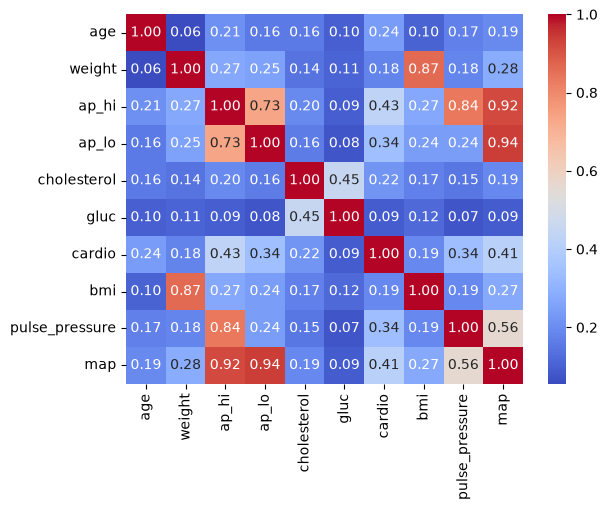

In [21]:
import seaborn as sns


sns.heatmap(df_clean.corr(), annot=True, cmap='coolwarm', fmt=".2f")


In [22]:
df_clean = df_clean.drop(columns=['weight', 'ap_lo'])

In [23]:
from sklearn.model_selection import train_test_split

x = df_clean.drop(columns=['cardio'])
y = df_clean['cardio']

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [24]:
X_train.corrwith(y_train).sort_values(ascending=False)

ap_hi             0.428943
map               0.410381
pulse_pressure    0.337178
age               0.237339
cholesterol       0.219346
bmi               0.188498
gluc              0.087730
dtype: float64

<Axes: >

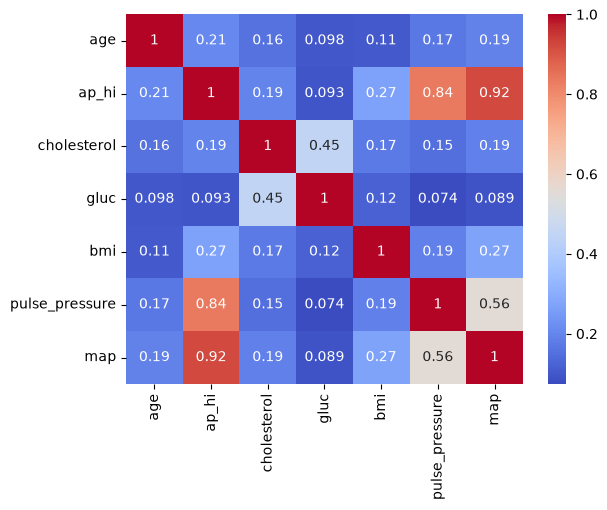

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.heatmap(X_train.corr(), annot=True, cmap='coolwarm')

Total rows: 26083
Unique patient profiles: 302


In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
cols_to_scale = ['ap_hi', 'bmi', 'pulse_pressure', 'map']

X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

In [29]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score

# 1. Initialize the model (n_jobs=-1 uses all your CPU cores)
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)

# 2. Train on the scaled training data
rf_model.fit(X_train, y_train)

# 3. Predict on the test data
y_pred = rf_model.predict(X_test)

# 4. Evaluate performance
print(classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print(accuracy_score(y_test, y_pred))




              precision    recall  f1-score   support

           0       0.71      0.79      0.75      6931
           1       0.76      0.67      0.71      6777

    accuracy                           0.73     13708
   macro avg       0.74      0.73      0.73     13708
weighted avg       0.74      0.73      0.73     13708

Confusion Matrix:
 [[5501 1430]
 [2242 4535]]
0.732127224978115


Allah akbar 3la el data Leakage ///////this comment was for the old dataset, I found a better one, no way to fuse them together since they had different criteria, so i just choosed the larger one

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

#the parameteres are updated after hyperparameter tuning using RandomizedSearchCV

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.7,
    gamma =0.2,
    colsample_bytree=0.9,
    reg_lambda=1.0,
    reg_alpha=5.0, 
    min_child_weight=5,
    random_state=42
)
xgb_model.fit(X_train, y_train)

# 1. Standard 0.50 threshold
xgb_preds = xgb_model.predict(X_test)
print("XGB Accuracy (0.50):", accuracy_score(y_test, xgb_preds))
print(confusion_matrix(y_test, xgb_preds))
print(classification_report(y_test, xgb_preds))

# 2. Medical Recall threshold (0.45)
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]
xgb_preds_045 = (xgb_probs >= 0.45).astype(int)
print("\nXGB Confusion Matrix (0.45):\n", confusion_matrix(y_test, xgb_preds_045))
print(classification_report(y_test, xgb_preds_045))

XGB Accuracy (0.50): 0.7354099795739714
[[5421 1510]
 [2117 4660]]
              precision    recall  f1-score   support

           0       0.72      0.78      0.75      6931
           1       0.76      0.69      0.72      6777

    accuracy                           0.74     13708
   macro avg       0.74      0.73      0.73     13708
weighted avg       0.74      0.74      0.73     13708


XGB Confusion Matrix (0.45):
 [[5127 1804]
 [1778 4999]]
              precision    recall  f1-score   support

           0       0.74      0.74      0.74      6931
           1       0.73      0.74      0.74      6777

    accuracy                           0.74     13708
   macro avg       0.74      0.74      0.74     13708
weighted avg       0.74      0.74      0.74     13708



In [31]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score

param_dist = {
    'n_estimators': [200, 300, 400, 500],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.03, 0.05, 0.08],
    'min_child_weight': [1, 5, 10, 15],  # Higher values prevent fitting to noisy BP buckets
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'gamma': [0, 0.1, 0.2, 0.5],
    'reg_alpha': [0, 0.1, 1.0, 5.0],     # L1 regularization
    'reg_lambda': [1.0, 2.0, 5.0, 10.0]  # L2 regularization
}

xgb_base = XGBClassifier(random_state=42, eval_metric='logloss')

random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_dist,
    n_iter=25,
    scoring='roc_auc',
    cv=5,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best CV ROC-AUC:", random_search.best_score_)

# Evaluate the best estimator on X_test
best_xgb = random_search.best_estimator_
best_probs = best_xgb.predict_proba(X_test)[:, 1]
best_preds_042 = (best_probs >= 0.42).astype(int)  # 0.42 pushes Recall past ~0.77

print("\nTest Accuracy (0.50):", accuracy_score(y_test, best_xgb.predict(X_test)))
print("Test ROC-AUC:", roc_auc_score(y_test, best_probs))
print("\nConfusion Matrix (0.42 threshold):\n", confusion_matrix(y_test, best_preds_042))
print(classification_report(y_test, best_preds_042))

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best Parameters: {'subsample': 0.7, 'reg_lambda': 1.0, 'reg_alpha': 5.0, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.03, 'gamma': 0.2, 'colsample_bytree': 0.9}
Best CV ROC-AUC: 0.7989130119690658

Test Accuracy (0.50): 0.7354099795739714
Test ROC-AUC: 0.8016732292789225

Confusion Matrix (0.42 threshold):
 [[4863 2068]
 [1593 5184]]
              precision    recall  f1-score   support

           0       0.75      0.70      0.73      6931
           1       0.71      0.76      0.74      6777

    accuracy                           0.73     13708
   macro avg       0.73      0.73      0.73     13708
weighted avg       0.73      0.73      0.73     13708

